# Foundermatcha — Objective 1: Data Cleaning & Integration
**Project:** Foundermatcha User Journey Analytics  
**Objective:** Clean, integrate, and validate the users, matches, and events datasets  
**Files needed:** `users.csv`, `matches.csv`, `events.csv` — place them in the same folder as this notebook


In [11]:
# ── Step 1: Install & Import Libraries ──────────────────────────────────
# Run this cell first. If any library is missing, pip install it.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries loaded successfully")
print(f"   pandas  {pd.__version__}")
print(f"   numpy   {np.__version__}")

✅ Libraries loaded successfully
   pandas  3.0.0
   numpy   2.4.2


In [12]:
# ── Step 2: Load Raw Data ────────────────────────────────────────────────
# Make sure users.csv, matches.csv, events.csv are in the same folder as this notebook.

users   = pd.read_csv('../data/users.csv')
matches = pd.read_csv('../data/matches.csv')
events  = pd.read_csv('../data/events.csv')

print("RAW ROW COUNTS (expected: users≈2030, matches≈1917, events≈14073)")
print(f"  users   : {len(users):,} rows, {users.shape[1]} columns")
print(f"  matches : {len(matches):,} rows, {matches.shape[1]} columns")
print(f"  events  : {len(events):,} rows, {events.shape[1]} columns")

RAW ROW COUNTS (expected: users≈2030, matches≈1917, events≈14073)
  users   : 2,030 rows, 16 columns
  matches : 1,917 rows, 15 columns
  events  : 14,073 rows, 9 columns


In [13]:
# ── Step 3: Audit Raw Data — Understand Every Problem ───────────────────
# Run this to see all issues before cleaning anything.

print("=" * 60)
print("USERS — Missing values")
print("=" * 60)
print(users.isnull().sum())
print()
print("Unique values per messy column:")
for col in ['user_type','location','availability','equity_comfort',
            'age_band','education_level','personality_type']:
    print(f"  {col}: {list(users[col].unique())}")

print()
print("=" * 60)
print("MATCHES — Missing values")
print("=" * 60)
print(matches.isnull().sum())
print()
print("Boolean columns (should be True/False — check for mixed formats):")
for col in ['availability_compatibility','compensation_compatibility',
            'prior_connection','match_viewed_by_founder',
            'match_viewed_by_engineer','intro_requested','intro_sent']:
    print(f"  {col}: {list(matches[col].unique())}")

print()
print("=" * 60)
print("EVENTS — Missing values")
print("=" * 60)
print(events.isnull().sum())
print()
print(f"  event_type unique values: {list(events['event_type'].unique())}")
print(f"  days_since_signup range : {events['days_since_signup'].min()} to {events['days_since_signup'].max()}")
print(f"  Duplicates              : {events.duplicated().sum()}")

USERS — Missing values
user_id                              0
user_type                            0
signup_date                          0
acquisition_source                   0
location                             0
age_band                            42
education_level                     80
prior_startup_experience             0
availability                         0
compensation_preference              0
equity_comfort                       0
personality_type                    47
developer_experience_years         799
seniority_level                    799
profile_completeness_at_signup      92
referred_by_user_id               1677
dtype: int64

Unique values per messy column:
  user_type: ['engineer', 'founder']
  location: ['London', 'Bristol', 'Remote', 'remote', ' London ', 'Manchester', 'MCR', 'International', 'manchester', 'london', 'bristol', 'REMOTE', 'international', 'LDN', 'Intl']
  availability: ['Full-time', 'PT', 'evenings', 'part-time', 'Part Time', 'evenings only'

In [14]:
# ── Step 4: Clean USERS ──────────────────────────────────────────────────

users_clean = users.copy()

# 4a. Remove duplicate rows
before = len(users_clean)
users_clean = users_clean.drop_duplicates()
print(f"[4a] Duplicates removed : {before - len(users_clean)}")

# 4b. Parse signup_date to proper datetime
users_clean['signup_date'] = pd.to_datetime(users_clean['signup_date'], errors='coerce')
print(f"[4b] signup_date parsed. Invalid dates: {users_clean['signup_date'].isnull().sum()}")

# 4c. Standardise location — 15 messy variants → 5 canonical values
loc_map = {
    'london'       : 'London',
    'ldn'          : 'London',
    ' london '     : 'London',
    'manchester'   : 'Manchester',
    'mcr'          : 'Manchester',
    'bristol'      : 'Bristol',
    'remote'       : 'Remote',
    'international': 'International',
    'intl'         : 'International',
}
users_clean['location'] = (
    users_clean['location']
    .str.strip()
    .str.lower()
    .map(lambda x: loc_map.get(x, x.title()) if isinstance(x, str) else x)
)
print(f"[4c] Location variants now: {sorted(users_clean['location'].unique())}")

# 4d. Standardise availability — 10 variants → 3 canonical values
avail_map = {
    'full-time'    : 'full-time',
    'full time'    : 'full-time',
    'ft'           : 'full-time',
    'part-time'    : 'part-time',
    'part time'    : 'part-time',
    'pt'           : 'part-time',
    'evenings only': 'evenings only',
    'evenings'     : 'evenings only',
}
users_clean['availability'] = (
    users_clean['availability']
    .str.strip()
    .str.lower()
    .map(lambda x: avail_map.get(x, x) if isinstance(x, str) else x)
)
print(f"[4d] Availability variants now: {sorted(users_clean['availability'].unique())}")

# 4e. Convert equity_comfort from words to integers (zero→0, one→1 … five→5)
equity_word_map = {'zero': 0, 'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5}
users_clean['equity_comfort'] = (
    users_clean['equity_comfort']
    .astype(str).str.strip().str.lower()
    .map(lambda x: equity_word_map.get(x, x))
)
users_clean['equity_comfort'] = pd.to_numeric(users_clean['equity_comfort'], errors='coerce')
print(f"[4e] equity_comfort unique: {sorted(users_clean['equity_comfort'].dropna().unique())}")

# 4f. Fix profile_completeness_at_signup — cap at 100, fill missing with median
over_100 = (users_clean['profile_completeness_at_signup'] > 100).sum()
users_clean['profile_completeness_at_signup'] = users_clean['profile_completeness_at_signup'].clip(upper=100)
median_pc = users_clean['profile_completeness_at_signup'].median()
users_clean['profile_completeness_at_signup'] = users_clean['profile_completeness_at_signup'].fillna(median_pc)
print(f"[4f] profile_completeness: {over_100} values capped at 100, missing filled with median ({median_pc})")

# 4g. Replace 'unknown' strings with NaN, then fill with mode
for col in ['age_band', 'education_level', 'personality_type']:
    users_clean[col] = users_clean[col].replace('unknown', np.nan)
    mode_val = users_clean[col].mode()[0]
    missing_count = users_clean[col].isnull().sum()
    users_clean[col] = users_clean[col].fillna(mode_val)
    print(f"[4g] {col}: {missing_count} missing filled with mode='{mode_val}'")

# NOTE: developer_experience_years, seniority_level blank for founders — INTENTIONAL, do not fill
# NOTE: referred_by_user_id blank = not referred — INTENTIONAL, do not fill

print()
print(f"✅ users_clean: {len(users_clean):,} rows")

[4a] Duplicates removed : 30
[4b] signup_date parsed. Invalid dates: 0
[4c] Location variants now: ['Bristol', 'International', 'London', 'Manchester', 'Remote']
[4d] Availability variants now: ['evenings only', 'full-time', 'part-time']
[4e] equity_comfort unique: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
[4f] profile_completeness: 14 values capped at 100, missing filled with median (48.5)
[4g] age_band: 59 missing filled with mode='25-34'
[4g] education_level: 109 missing filled with mode='undergraduate'
[4g] personality_type: 68 missing filled with mode='Sentinel'

✅ users_clean: 2,000 rows


In [15]:
# ── Step 4h: Add imputation flag columns (users) ─────────────────────────
# Uses user_id to align rows — NOT positional assignment.
# (Raw file has 2,030 rows; users_clean has 2,000 — lengths differ.)

users_raw_temp = pd.read_csv('../data/users.csv')

imputed_user_ids = set(
    users_raw_temp[
        users_raw_temp['personality_type'].isnull() |
        (users_raw_temp['personality_type'] == 'unknown')
    ]['user_id']
)

users_clean['personality_type_imputed'] = users_clean['user_id'].isin(imputed_user_ids).astype(int)
print(f"[4h] personality_type_imputed: {users_clean['personality_type_imputed'].sum()} rows flagged")

[4h] personality_type_imputed: 68 rows flagged


In [16]:
# ── Step 5: Clean MATCHES ────────────────────────────────────────────────

matches_clean = matches.copy()

# 5a. Parse match_suggested_date
matches_clean['match_suggested_date'] = pd.to_datetime(
    matches_clean['match_suggested_date'], errors='coerce'
)
print(f"[5a] match_suggested_date parsed. Invalid: {matches_clean['match_suggested_date'].isnull().sum()}")

# 5b. Standardise all boolean columns — True/Yes → True, False/No → False
bool_cols = [
    'availability_compatibility', 'compensation_compatibility', 'prior_connection',
    'match_viewed_by_founder', 'match_viewed_by_engineer',
    'intro_requested', 'intro_sent'
]
true_vals = {'true', 'yes'}
for col in bool_cols:
    matches_clean[col] = (
        matches_clean[col]
        .astype(str).str.strip().str.lower()
        .map(lambda x: True if x in true_vals else False)
    )
print(f"[5b] Boolean columns standardised: {bool_cols}")

# 5c. Fill missing algorithm_score with median
algo_median = matches_clean['algorithm_score'].median()
missing_algo = matches_clean['algorithm_score'].isnull().sum()
matches_clean['algorithm_score'] = matches_clean['algorithm_score'].fillna(algo_median)
print(f"[5c] algorithm_score: {missing_algo} missing filled with median ({algo_median:.1f})")

# NOTE: days_to_outcome blank = match still pending — INTENTIONAL, do not fill

print()
print(f"✅ matches_clean: {len(matches_clean):,} rows")
print(f"   outcome distribution:")
print(matches_clean['outcome'].value_counts().to_string())

[5a] match_suggested_date parsed. Invalid: 0
[5b] Boolean columns standardised: ['availability_compatibility', 'compensation_compatibility', 'prior_connection', 'match_viewed_by_founder', 'match_viewed_by_engineer', 'intro_requested', 'intro_sent']
[5c] algorithm_score: 54 missing filled with median (52.0)

✅ matches_clean: 1,917 rows
   outcome distribution:
outcome
pending           1362
meeting_booked     415
ghosted             79
declined            61


In [17]:
# ── Step 5b: Add algorithm_score_imputed flag (matches) ──────────────────
# Uses match_id to align rows — safe regardless of row counts.

matches_raw_temp = pd.read_csv('../data/matches.csv')

imputed_match_ids = set(
    matches_raw_temp[matches_raw_temp['algorithm_score'].isnull()]['match_id']
)

matches_clean['algorithm_score_imputed'] = matches_clean['match_id'].isin(imputed_match_ids).astype(int)
print(f"[5b] algorithm_score_imputed: {matches_clean['algorithm_score_imputed'].sum()} rows flagged")

[5b] algorithm_score_imputed: 54 rows flagged


In [18]:
# ── Step 6: Clean EVENTS ─────────────────────────────────────────────────

events_clean = events.copy()

# 6a. Remove duplicate rows
before = len(events_clean)
events_clean = events_clean.drop_duplicates()
print(f"[6a] Duplicate rows removed: {before - len(events_clean)}")

# 6b. Parse event_timestamp
events_clean['event_timestamp'] = pd.to_datetime(events_clean['event_timestamp'], errors='coerce')
print(f"[6b] event_timestamp parsed. Invalid: {events_clean['event_timestamp'].isnull().sum()}")

# 6c. Standardise event_type — strip spaces, lowercase
#     27 messy variants → 9 clean canonical values
events_clean['event_type'] = events_clean['event_type'].str.strip().str.lower()
print(f"[6c] event_type unique values now: {sorted(events_clean['event_type'].unique())}")

# 6d. Drop rows with negative days_since_signup (corrupted — event before signup is impossible)
bad = (events_clean['days_since_signup'] < 0).sum()
events_clean = events_clean[events_clean['days_since_signup'] >= 0]
print(f"[6d] Rows with negative days_since_signup removed: {bad}")

# 6e. Fill missing device_type and platform with 'unknown'
events_clean['device_type'] = events_clean['device_type'].fillna('unknown')
events_clean['platform']    = events_clean['platform'].fillna('unknown')
print(f"[6e] Missing device_type and platform filled with 'unknown'")

# NOTE: match_id blank for non-match events (signup, email_verified etc.) — INTENTIONAL

print()
print(f"✅ events_clean: {len(events_clean):,} rows")
print(f"   event_type distribution:")
print(events_clean['event_type'].value_counts().to_string())

[6a] Duplicate rows removed: 139
[6b] event_timestamp parsed. Invalid: 0
[6c] event_type unique values now: ['dropped_off', 'email_verified', 'intro_requested', 'intro_sent', 'match_suggested', 'match_viewed', 'meeting_booked', 'profile_updated', 'signup']
[6d] Rows with negative days_since_signup removed: 1303
[6e] Missing device_type and platform filled with 'unknown'

✅ events_clean: 12,631 rows
   event_type distribution:
event_type
match_suggested    3047
match_viewed       2135
signup             2000
email_verified     1842
profile_updated    1401
intro_requested     637
dropped_off         599
intro_sent          555
meeting_booked      415


In [19]:
# ── Step 7: Validation — Check Everything Looks Correct ─────────────────

print("=" * 60)
print("FINAL VALIDATION")
print("=" * 60)

print("\nUSERS CLEAN:")
print(f"  Rows            : {len(users_clean):,}  (expected ~2,000)")
print(f"  Duplicates      : {users_clean.duplicated().sum()}")
print(f"  location unique : {sorted(users_clean['location'].unique())}")
print(f"  availability    : {sorted(users_clean['availability'].unique())}")
print(f"  equity_comfort  : {sorted(users_clean['equity_comfort'].dropna().unique())}")
print(f"  profile_max     : {users_clean['profile_completeness_at_signup'].max()} (should be ≤100)")
print(f"  Missing age_band: {users_clean['age_band'].isnull().sum()} (should be 0)")

print("\nMATCHES CLEAN:")
print(f"  Rows            : {len(matches_clean):,}  (expected 1,917)")
print(f"  Duplicates      : {matches_clean.duplicated().sum()}")
print(f"  Missing algo    : {matches_clean['algorithm_score'].isnull().sum()} (should be 0)")
print(f"  intro_sent dist : {matches_clean['intro_sent'].value_counts().to_dict()}")
print(f"  outcome dist    : {matches_clean['outcome'].value_counts().to_dict()}")

print("\nEVENTS CLEAN:")
print(f"  Rows              : {len(events_clean):,}  (expected ~12,600)")
print(f"  Duplicates        : {events_clean.duplicated().sum()}")
print(f"  Min days_since_sig: {events_clean['days_since_signup'].min()} (should be ≥0)")
print(f"  event_type count  : {events_clean['event_type'].nunique()} unique (should be 9)")

print("\nFOREIGN KEY CHECKS:")
match_founders = set(matches_clean['founder_id'])
match_engineers = set(matches_clean['engineer_id'])
user_ids = set(users_clean['user_id'])
orphan_founders  = match_founders - user_ids
orphan_engineers = match_engineers - user_ids
print(f"  Match founder_ids not in users : {len(orphan_founders)}")
print(f"  Match engineer_ids not in users: {len(orphan_engineers)}")

print("\n✅ Validation complete")

FINAL VALIDATION

USERS CLEAN:
  Rows            : 2,000  (expected ~2,000)
  Duplicates      : 0
  location unique : ['Bristol', 'International', 'London', 'Manchester', 'Remote']
  availability    : ['evenings only', 'full-time', 'part-time']
  equity_comfort  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
  profile_max     : 100.0 (should be ≤100)
  Missing age_band: 0 (should be 0)

MATCHES CLEAN:
  Rows            : 1,917  (expected 1,917)
  Duplicates      : 0
  Missing algo    : 0 (should be 0)
  intro_sent dist : {False: 1362, True: 555}
  outcome dist    : {'pending': 1362, 'meeting_booked': 415, 'ghosted': 79, 'declined': 61}

EVENTS CLEAN:
  Rows              : 12,631  (expected ~12,600)
  Duplicates        : 0
  Min days_since_sig: 0 (should be ≥0)
  event_type count  : 9 unique (should be 9)

FOREIGN KEY CHECKS:
  Match founder_ids not in users : 15
  Match engineer_ids not in users: 22

✅ Validation complete


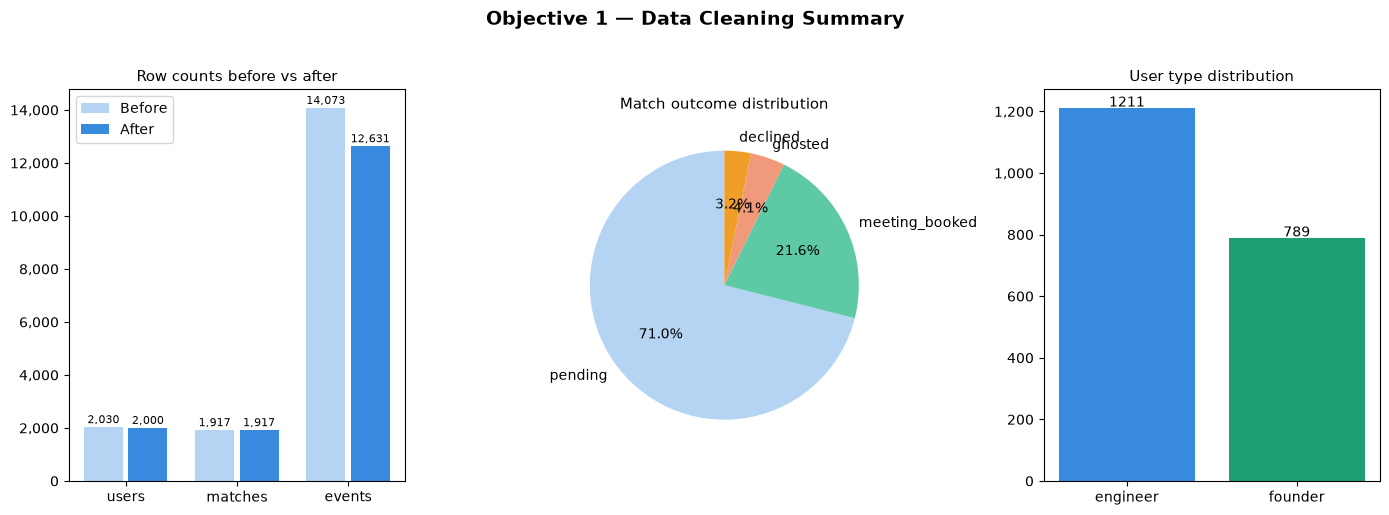

Chart saved as objective1_cleaning_summary.png


In [20]:
# ── Step 8: Summary Cleaning Chart ──────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Objective 1 — Data Cleaning Summary', fontsize=14, fontweight='bold', y=1.02)

# Chart 1: Row counts before vs after
files    = ['users', 'matches', 'events']
before_r = [2030, 1917, 14073]
after_r  = [len(users_clean), len(matches_clean), len(events_clean)]
x = range(len(files))
bars1 = axes[0].bar([i - 0.2 for i in x], before_r, 0.35, label='Before', color='#B5D4F4')
bars2 = axes[0].bar([i + 0.2 for i in x], after_r,  0.35, label='After',  color='#378ADD')
axes[0].set_title('Row counts before vs after', fontsize=11)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(files)
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
for bar in bars1: axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+50,
    f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=8)
for bar in bars2: axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+50,
    f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=8)

# Chart 2: Match outcomes
outcome_counts = matches_clean['outcome'].value_counts()
colors = ['#B5D4F4', '#5DCAA5', '#F0997B', '#EF9F27']
axes[1].pie(outcome_counts.values, labels=outcome_counts.index,
            autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Match outcome distribution', fontsize=11)

# Chart 3: User type split
user_type_counts = users_clean['user_type'].value_counts()
axes[2].bar(user_type_counts.index, user_type_counts.values,
            color=['#378ADD', '#1D9E75'])
axes[2].set_title('User type distribution', fontsize=11)
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
for i, v in enumerate(user_type_counts.values):
    axes[2].text(i, v + 5, str(v), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('objective1_cleaning_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as objective1_cleaning_summary.png")

In [21]:
# ── Step 9: Save Cleaned Files ───────────────────────────────────────────

users_clean.to_csv('../data/users_clean.csv',   index=False)
matches_clean.to_csv('../data/matches_clean.csv', index=False)
events_clean.to_csv('../data/events_clean.csv',  index=False)

print("✅ Cleaned files saved to your working directory:")
print("   users_clean.csv")
print("   matches_clean.csv")
print("   events_clean.csv")
print()
print("These files are the input for all subsequent objectives.")
print("Objective 1 complete — ready for Objective 2: Funnel & Journey Analysis")

✅ Cleaned files saved to your working directory:
   users_clean.csv
   matches_clean.csv
   events_clean.csv

These files are the input for all subsequent objectives.
Objective 1 complete — ready for Objective 2: Funnel & Journey Analysis
